In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

In [3]:
df = df.drop_duplicates().dropna()
X = df.drop("target", axis=1)
y = df["target"].astype(int).values

In [4]:
X = pd.get_dummies(X, drop_first=True).astype(float).values

In [5]:

np.random.seed(42)

train_indices = []
test_indices = []

for cls in np.unique(y):
    cls_indices = np.where(y == cls)[0]
    np.random.shuffle(cls_indices)

    split = int(0.8 * len(cls_indices))
    train_indices.extend(cls_indices[:split])
    test_indices.extend(cls_indices[split:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

np.random.shuffle(train_indices)
np.random.shuffle(test_indices)

X_train = X[train_indices]
y_train = y[train_indices]

X_test = X[test_indices]
y_test = y[test_indices]

In [6]:

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [7]:

def accuracy_score_manual(y_true, y_pred):
    return np.mean(y_true == y_pred)


def calculate_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Accuracy": accuracy_score_manual(y_true, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

In [8]:

class ManualLogisticRegression:
    def __init__(self, learning_rate=0.05, epochs=500, l2=0.01):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).reshape(-1, 1)

        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        self.std[self.std == 0] = 1
        X = (X - self.mean) / self.std

        self.weights = np.zeros((X.shape[1], 1))
        self.bias = 0.0
        n = len(X)

        for _ in range(self.epochs):
            probabilities = self.sigmoid(X @ self.weights + self.bias)

            dw = (X.T @ (probabilities - y)) / n
            dw += self.l2 * self.weights
            db = np.mean(probabilities - y)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        X = (np.asarray(X, dtype=float) - self.mean) / self.std
        probabilities = self.sigmoid(X @ self.weights + self.bias)
        return probabilities.ravel()

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

In [9]:

class ManualDecisionTree:
    def __init__(self, max_depth=3, min_samples=5):
        self.max_depth = max_depth
        self.min_samples = min_samples

    def gini(self, y):
        if len(y) == 0:
            return 0
        p = np.mean(y)
        return 2 * p * (1 - p)

    def best_split(self, X, y):
        best_gain = 0
        best_feature = None
        best_threshold = None

        parent_gini = self.gini(y)
        n = len(y)

        for feature in range(X.shape[1]):
            values = np.unique(X[:, feature])

            if len(values) > 20:
                values = np.percentile(values, np.linspace(5, 95, 10))

            for threshold in values:
                left = X[:, feature] <= threshold
                right = ~left

                if left.sum() < self.min_samples:
                    continue
                if right.sum() < self.min_samples:
                    continue

                child_gini = (
                    left.sum() / n * self.gini(y[left]) +
                    right.sum() / n * self.gini(y[right])
                )

                gain = parent_gini - child_gini

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold

    def build(self, X, y, depth):
        node = {"prediction": int(np.mean(y) >= 0.5)}

        if (
            depth >= self.max_depth or
            len(y) < 2 * self.min_samples or
            len(np.unique(y)) == 1
        ):
            return node

        feature, threshold = self.best_split(X, y)

        if feature is None:
            return node

        left = X[:, feature] <= threshold
        right = ~left

        node["feature"] = feature
        node["threshold"] = threshold
        node["left"] = self.build(X[left], y[left], depth + 1)
        node["right"] = self.build(X[right], y[right], depth + 1)

        return node

    def fit(self, X, y):
        self.tree = self.build(np.asarray(X), np.asarray(y), 0)
        return self

    def predict_one(self, row, node):
        if "feature" not in node:
            return node["prediction"]

        if row[node["feature"]] <= node["threshold"]:
            return self.predict_one(row, node["left"])

        return self.predict_one(row, node["right"])

    def predict(self, X):
        return np.array([
            self.predict_one(row, self.tree)
            for row in np.asarray(X)
        ])

In [10]:

class ManualKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        probabilities = []

        for row in X:
            distances = np.sqrt(np.sum((self.X - row) ** 2, axis=1))
            nearest = np.argsort(distances)[:self.k]
            probabilities.append(np.mean(self.y[nearest]))

        return np.array(probabilities)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

In [11]:

def create_base_models():
    return [
        ManualLogisticRegression(
            learning_rate=0.05, epochs=500, l2=0.01
        ),
        ManualDecisionTree(max_depth=3, min_samples=5),
        ManualKNN(k=5)
    ]

In [12]:

def stratified_kfold_indices(y, n_splits=5, seed=42):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(n_splits)]

    for cls in np.unique(y):
        indices = np.where(y == cls)[0]
        rng.shuffle(indices)
        chunks = np.array_split(indices, n_splits)

        for i, chunk in enumerate(chunks):
            folds[i].extend(chunk.tolist())

    return [np.array(fold, dtype=int) for fold in folds]

In [13]:

n_splits = 5

if min(np.sum(y_train == 0), np.sum(y_train == 1)) < n_splits:
    raise ValueError("Not enough examples per class for 5-fold CV.")

folds = stratified_kfold_indices(y_train, n_splits=n_splits)

oof_predictions = np.zeros((len(X_train), 3))

for fold_number in range(n_splits):
    validation_indices = folds[fold_number]

    training_indices = np.concatenate([
        folds[j] for j in range(n_splits)
        if j != fold_number
    ])

    X_fold_train = X_train[training_indices]
    y_fold_train = y_train[training_indices]

    X_fold_val = X_train[validation_indices]

    models = create_base_models()

    for model_index, model in enumerate(models):
        model.fit(X_fold_train, y_fold_train)

        if hasattr(model, "predict_proba"):
            predictions = model.predict_proba(X_fold_val)
        else:
            predictions = model.predict(X_fold_val)

        oof_predictions[validation_indices, model_index] = predictions

    print(f"Completed fold {fold_number + 1}/{n_splits}")

Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


In [14]:

meta_model = ManualLogisticRegression(
    learning_rate=0.05,
    epochs=1000,
    l2=0.01
)

meta_model.fit(oof_predictions, y_train)

In [15]:

final_base_models = create_base_models()

for model in final_base_models:
    model.fit(X_train, y_train)


test_meta_features = np.zeros((len(X_test), 3))

for model_index, model in enumerate(final_base_models):
    if hasattr(model, "predict_proba"):
        test_meta_features[:, model_index] = model.predict_proba(X_test)
    else:
        test_meta_features[:, model_index] = model.predict(X_test)

stacked_probabilities = meta_model.predict_proba(test_meta_features)
stacked_predictions = (stacked_probabilities >= 0.5).astype(int)

In [16]:

results = []

for i, model in enumerate(final_base_models):
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)
        predictions = (probabilities >= 0.5).astype(int)
    else:
        predictions = model.predict(X_test)

    results.append({
        "Model": ["Logistic Regression", "Decision Tree", "k-NN"][i],
        **calculate_metrics(y_test, predictions)
    })

results.append({
    "Model": "Stacked Model",
    **calculate_metrics(y_test, stacked_predictions)
})

results_df = pd.DataFrame(results)

print("\nModel Comparison")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("stacking_model_comparison.csv", index=False)


Model Comparison
              Model  Accuracy  Precision  Recall  F1 Score  TP  TN  FP  FN
Logistic Regression    0.7869     0.7778  0.8485    0.8116  28  20   8   5
      Decision Tree    0.8033     0.7838  0.8788    0.8286  29  20   8   4
               k-NN    0.7869     0.7778  0.8485    0.8116  28  20   8   5
      Stacked Model    0.8197     0.8056  0.8788    0.8406  29  21   7   4


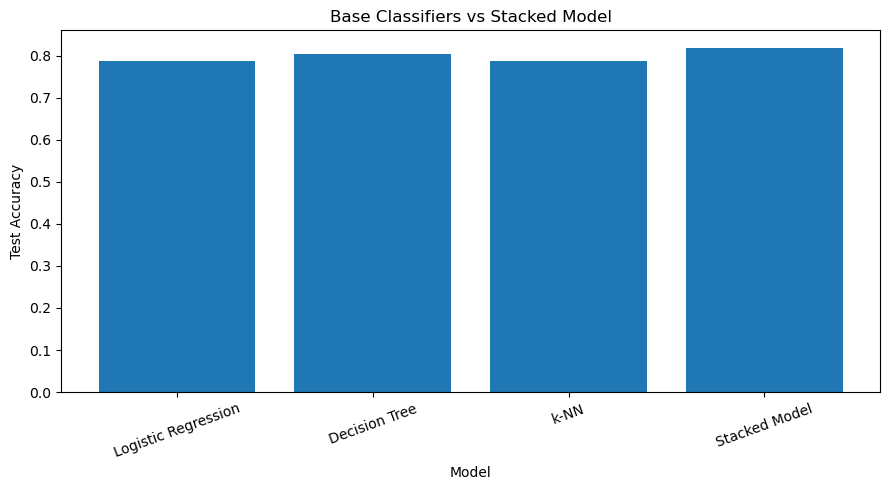

In [17]:

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.title("Base Classifiers vs Stacked Model")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [18]:

tp = np.sum((y_test == 1) & (stacked_predictions == 1))
tn = np.sum((y_test == 0) & (stacked_predictions == 0))
fp = np.sum((y_test == 0) & (stacked_predictions == 1))
fn = np.sum((y_test == 1) & (stacked_predictions == 0))

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

print("\nStacked Model Confusion Matrix")
print("Rows = Actual [0, 1], Columns = Predicted [0, 1]")
print(confusion_matrix)


Stacked Model Confusion Matrix
Rows = Actual [0, 1], Columns = Predicted [0, 1]
[[21  7]
 [ 4 29]]
